In [19]:
from gauge_arbitrage.vf import detector, vf_series
import numpy as np

T, n, d, N = 200, 200, 18, 20

rng=np.random.default_rng(seed=0)

beta_a=rng.uniform(low=-0.0001, high=0.0001, size=(d))                                        
sigma=np.insert(rng.uniform(low=-0.001, high=0.001, size=(N, d)),0,  np.zeros(d), axis=0)   
alpha_A=rng.uniform(low=-0.0001, high=0.0001, size=(2))  
            
series = vf_series.Vf_series(T, n)
Z = rng.standard_normal((T, d)) 
X=series.X_mu_43(sigma, beta_a, alpha_A, 1, Z)

R = detector.calc_R(X)
signals = detector.run_detector(R, L=100, n_dirs=2, use_cash=False)

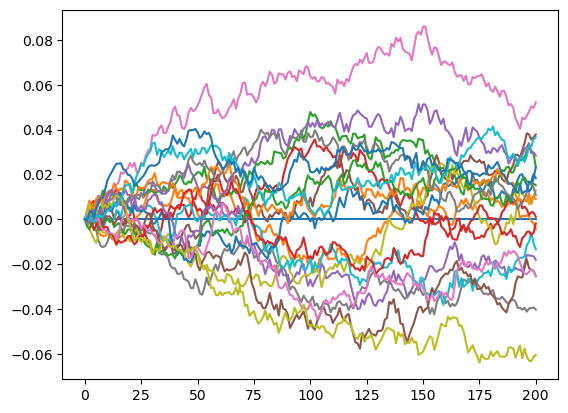

In [20]:
#Compare to V&F Figure 1
import matplotlib.pyplot as plt
fig_1, ax_1=plt.subplots(1,1)
rng2=np.random.default_rng()

#plot 20 random walks
for i in range(21):
    ax_1.plot(series.times, np.log(X[:, i]))

In [21]:
arr=signals['products']
A2_values=arr[~np.isnan(arr)]

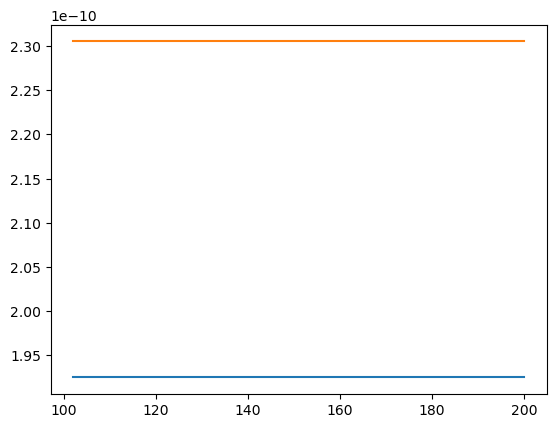

In [22]:
fig, ax=plt.subplots(1,1)
ax.plot(series.times[102:], A2_values, label='Detector value')
ax.plot(series.times[102:], np.zeros(99)+(alpha_A@alpha_A), label='Theoretical value')

In [ ]:
np.mean(A2_values)

8.726987295927103e-11